# Contextualização do *Dataset Spaceship Titanic*

## Introdução

O [*dataset Spaceship Titanic*](https://www.kaggle.com/competitions/spaceship-titanic/overview) é uma variação do clássico *dataset* baseado no naufrágio de 1912. Com o mesmo objetivo do *dataset* original (prever quem sobreviveu ao incidente e quem não sobreviveu), esse *dataset* apresenta algumas modificações quanto às características para se encaixar no contexto de um cruzeiro espacial que teve parte de seus passageiros transportados para uma dimensão paralela.

## Instalação do optuna

In [3]:
!pip install optuna -qq

## Exploração inicial

In [4]:
import pandas as pd
import zipfile

# extrair do .zip
with zipfile.ZipFile('spaceship-titanic.zip', 'r') as zip_ref:
    zip_ref.extractall()

# visualização inicial dos dados
df = pd.read_csv('train.csv')
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## Descrição das Características

| Característica | Descrição |
| -------------- | --------- |
| *PassangerId* | Id do passageiro e do grupo que ele faz parte (geralmente família, mas não necessariamente) |
| *Home Planet* | Planeta de origem/estadia do passageiro |
| *Cryo Sleep* | Se o passageiro está em criossono durante a viagem |
| *Cabin* | Posição da cabine do passageiro |
| *Destination* | Planeta de destino do passageiro |
| *Age* | Idade do passageiro |
| *VIP* | Se o passageiro pagou pelo *VIP* |
| *Room Service* | Quantidade gasta em serviços de quarto pelo passageiro |
| *Food Court* | Quantidade gasta nos restaurantes pelo passageiro |
| *Shopping Mall* | Quantidade gasta nas lojas pelo passageiro |
| *Spa* | Quantidade gasta no Spa pelo passageiro |
| *VR Deck* | Quantidade gasta no setor de RV pelo passageiro |
| *Name* | Nome do passageiro |
| *Transported* | Se o passageiro foi transportado para outra dimensão (alvo) |

## Distribuição das classes alvo (com porcentagens)

Classes False: 4315/8693 (49.638%)
Classes True: 4378/8693 (50.362%)


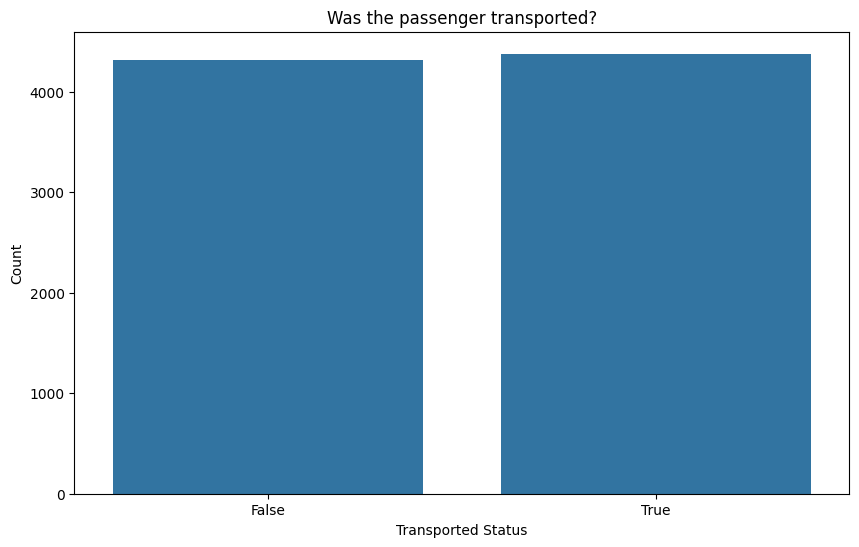

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

transported_col = df['Transported']

# Classes Distribution
labels, count = np.unique(transported_col, return_counts=True)
for i in range(len(labels)):
    print(f'Classes {labels[i]}: {count[i]}/{len(transported_col)} ({count[i] / len(transported_col):.3%})')

# Classes Distribution Figure
plt.figure(figsize=(10, 6))
sns.countplot(x=transported_col)
plt.title('Was the passenger transported?')
plt.xlabel('Transported Status')
plt.ylabel('Count')
plt.show()

# Preparação dos Dados

In [6]:
# separation between X and y
Xraw, y = df.drop(['Transported'], axis=1), df['Transported']
Xraw.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines


In [7]:
# breaking down the cabin into 3 columns
Xraw[['Deck', 'CabinNum', 'Side']] = Xraw['Cabin'].str.split('/', expand=True)
Xraw = Xraw.drop('Cabin', axis=1)
Xraw.tail()

,PassengerId,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Deck,CabinNum,Side
8688,9276_01,Europa,False,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,A,98,P
8689,9278_01,Earth,True,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,G,1499,S
8690,9279_01,Earth,False,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,G,1500,S
8691,9280_01,Europa,False,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,E,608,S
8692,9280_02,Europa,False,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,0.0,12.0,Propsh Hontichre,E,608,S


## *Pipeline* de preprocessamento

O pipeline de preprocessamento tem as seguintes etapas:
- *Desired Features*: Seleção das características desejadas no X;
- *Numeric Features*: Isolamento das características numéricas;
- *Categoric Features*: Isolamento das características categóricas;
- *Simple Imputer*: Resolução de dados nulos segundo uma estratégia dada (Média (*mean*) para as características numéricas e Moda (*most frequent* para as catacterísticas categóricas));
- *One Hot Encoder*: Trasformação das catacterísticas categóricas em numéricas segundo a estratégia *One Hot*; e
- *Dense Transformer*: Transformação da matriz esparsa que vem da união de *pipelines* numéricos e categóricos (por causa do *One Hot Encoder*) em uma matriz densa para continuar o processamento.

As etapas do preprocessamento são executadas segundo a sequência da imagem abaixo.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion

# return desired features
class DesiredFeatures(BaseEstimator, TransformerMixin):
  def __init__(self, features_to_drop: list[str] = []):
    self.features_to_drop = features_to_drop
    self
  def fit(self, X, y=None):
    return self
  def transform(self, X):
    return X.drop(self.features_to_drop, axis=1)

# return numeric features
class NumericFeatures(BaseEstimator, TransformerMixin):
  def __init__(self):
    self
  def fit(self, X, y=None):
    return self
  def transform(self, X):
    return X.select_dtypes(include='number')

# return categoric features
class CategoricFeatures(BaseEstimator, TransformerMixin):
  def __init__(self):
    self
  def fit(self, X, y=None):
    return self
  def transform(self, X):
    return X.select_dtypes(include='object')

# sparce to dense matrix
class DenseTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X, y=None):
        return X.toarray()

# pipelines
pipenum = Pipeline([
    ('numeric_features', NumericFeatures()),
    ('imputer', SimpleImputer(strategy='mean'))
])

pipecat = Pipeline([
    ('categoric_features', CategoricFeatures()),
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder())
])

numcat = FeatureUnion([
    ('pipenum', pipenum),
    ('pipecat', pipecat)
])

preproc = Pipeline([
    ('desired', DesiredFeatures(features_to_drop=["PassengerId", "CabinNum", "Name"])),
    ('numcat', numcat),
    ('dense', DenseTransformer())
])

preproc.fit(Xraw)

Pipeline(steps=[('desired',
                 DesiredFeatures(features_to_drop=['PassengerId', 'CabinNum',
                                                   'Name'])),
                ('numcat',
                 FeatureUnion(transformer_list=[('pipenum',
                                                 Pipeline(steps=[('numeric_features',
                                                                  NumericFeatures()),
                                                                 ('imputer',
                                                                  SimpleImputer())])),
                                                ('pipecat',
                                                 Pipeline(steps=[('categoric_features',
                                                                  CategoricFeatures()),
                                                                 ('imputer',
                                                                  SimpleImputer(strategy='most_frequent')),
                                                                 ('onehot',
                                                                  OneHotEncoder())]))])),
                ('dense', DenseTransformer())])

In [9]:
X = preproc.fit_transform(Xraw)
print(X[:5])

Xraw.head()

[[3.900e+01 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
  1.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+00
  1.000e+00 0.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00
  0.000e+00 0.000e+00 0.000e+00 1.000e+00 0.000e+00]
 [2.400e+01 1.090e+02 9.000e+00 2.500e+01 5.490e+02 4.400e+01 1.000e+00
  0.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+00
  1.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
  1.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+00]
 [5.800e+01 4.300e+01 3.576e+03 0.000e+00 6.715e+03 4.900e+01 0.000e+00
  1.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+00
  0.000e+00 1.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+00]
 [3.300e+01 0.000e+00 1.283e+03 3.710e+02 3.329e+03 1.930e+02 0.000e+00
  1.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+00
  1.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+

,PassengerId,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Deck,CabinNum,Side
0,0001_01,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,B,0,P
1,0002_01,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,F,0,S
2,0003_01,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,A,0,S
3,0003_02,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,A,0,S
4,0004_01,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,F,1,S


## Nova organização das colunas após a transformação do preprocessamento

In [10]:
print("Organização das colunas")
new_columns = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck",
               "HomePlanet: Earth", "HomePlanet: Europa", "HomePlanet: Mars",
               "CryoSleep: False", "CryoSleep: True",
               "Destination: Cancri", "Destination: PSO", "Destination: Trappist",
               "VIP: False", "VIP: True",
               "Deck: A", "Deck: B", "Deck: C", "Deck: D", "Deck: E", "Deck: F", "Deck: G", "Deck: T",
               "Side: P", "Side: S"]
print("\n".join(new_columns))

Organização das colunas
Age
RoomService
FoodCourt
ShoppingMall
Spa
VRDeck
HomePlanet: Earth
HomePlanet: Europa
HomePlanet: Mars
CryoSleep: False
CryoSleep: True
Destination: Cancri
Destination: PSO
Destination: Trappist
VIP: False
VIP: True
Deck: A
Deck: B
Deck: C
Deck: D
Deck: E
Deck: F
Deck: G
Deck: T
Side: P
Side: S


# Exploração e Visualização dos Dados

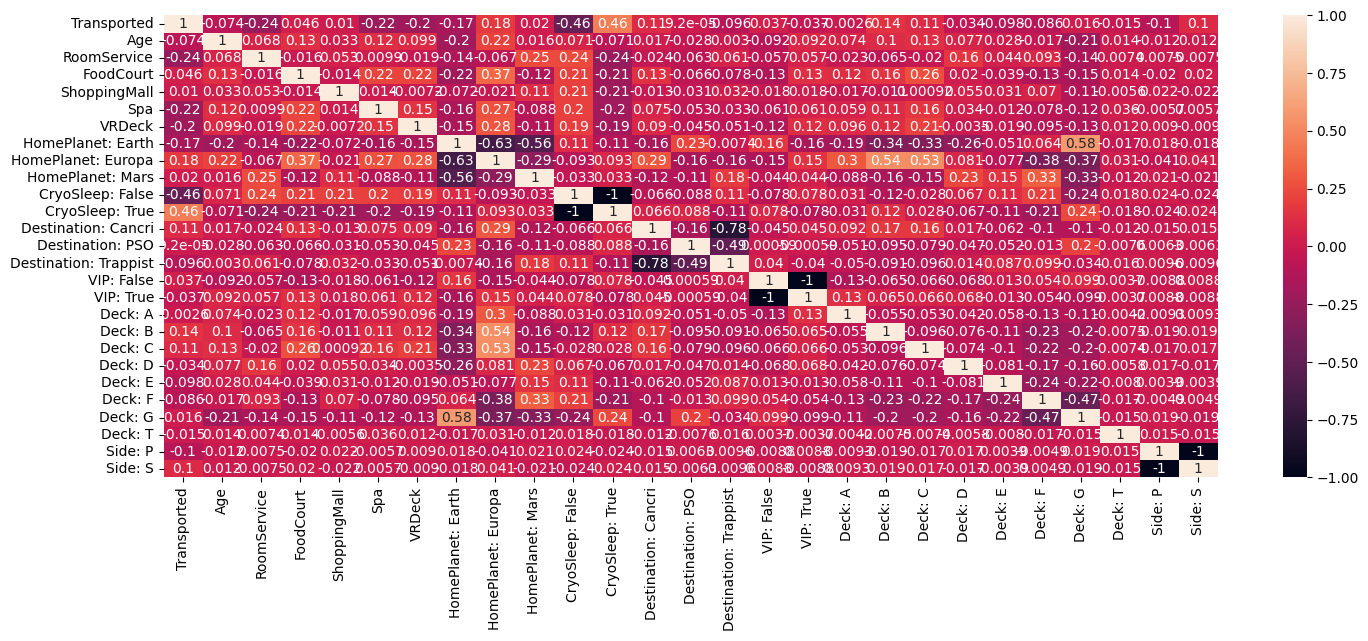

In [11]:
# corr matrix
plt.figure(figsize=(17, 6))
numDf = pd.DataFrame(X, columns=new_columns)
numDf.insert(0, 'Transported', y)
corr_matrix = numDf.corr()
sns.heatmap(corr_matrix, annot=True)
plt.show()

# Aplicação das Técnicas de Aprendizado de Máquina

In [14]:
# train and test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

## Linha de base e modelos usados

Para a classificação os modelos abaixo foram usados. Além disso, para a seleção dos parâmetros dos modelos foi usado a biblioteca Optuna para testar diversas combinações de parâmetros e escolher aquela com melhor performance.

### Zero R (*baseline*)
Um modelo simples que apenas adivinha a classe mais comum do treino no teste.
Esse modelo foi usado para criar uma base para avaliar os demais modelos.

### *K Nearest Neighbors* (KNN)
Modelo que cria uma votação para os K elementos do treino mais próximos do elemento do teste e, com base no resultado da votação, classifica-o.
A proximidade dos elementos pode ser calculada de várias formas (e.g. distância euclidiana, distância de Manhattan, distância de Minkowski).

#### Algumas fórmulas para cálculo da distância no KNN
> considere $d_i$ uma distância entre dois elementos em uma das características consideradas pelo modelo e que existem $x$ características consideradas que são numeradas de 1 a $x$.

$EuclideanDistance = \sqrt(\sum_{i=1}^x d_i^2)$

$ManhattanDistance = \sum_{i=1}^x d_i$

$MinkowskiDistance = \sum_{i=1}^x |d_i|$

### *Random Forest*
*Ensemble* que cria diversas árvores de decisão com base nas características dadas. Após isso, a classificação de um caso é feita a partir de uma votação entre as classficações feitas por cada uma das árvores para o caso em questão.

### *Gradient Boosting*
*Ensemble* que cria diversas árvores de decisão sequencialmente, com o objetivo de, a cada iteração, "aprender" e corrigir os erros da iteração anterior.

In [15]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score
import numpy as np

def most_common(y):
    labels, count = np.unique(y, return_counts=True)
    return labels[np.argmax(count)]

class ZeroR(BaseEstimator, ClassifierMixin):
    def __init__(self):
        self
    def fit(self, X, y):
        self.answer = most_common(y)
    def predict(self, X):
        return np.full(X.shape[0], self.answer)

In [16]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
import optuna

class OptunaKNeighborsClassifier(BaseEstimator, ClassifierMixin):
  def __init__(self, n_trials: int = 100):
    self.n_trials = n_trials

  def fit(self, X, y):
    pipeline = Pipeline([
      ('scaler', StandardScaler()),
      ('knn', KNeighborsClassifier())
    ])

    def objective(trial):
      with_mean = trial.suggest_categorical("with_mean", [True, False])
      with_std = trial.suggest_categorical("with_std", [True, False])
      scaler = StandardScaler(with_mean=with_mean, with_std=with_std)

      n_neighbors = trial.suggest_int("n_neighbors", 1, 100)
      weights = trial.suggest_categorical("weights", ["uniform", "distance"])
      metric = trial.suggest_categorical("metric", ["euclidean", "manhattan", "chebyshev", "minkowski"])
      model = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric)

      splitter = StratifiedKFold(n_splits=5, shuffle=True)

      scores = cross_validate(pipeline, X, y, cv=splitter, scoring='accuracy')
      accuracy = scores['test_score']
      return accuracy.mean()

    study = optuna.create_study(direction='maximize')
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study.optimize(objective, n_trials=self.n_trials, show_progress_bar=True)

    best_params = study.best_params
    scaler_params = {
        'with_mean': best_params['with_mean'],
        'with_std': best_params['with_std']
    }
    knn_params = {
        'n_neighbors': best_params['n_neighbors'],
        'weights': best_params['weights'],
        'metric': best_params['metric']
    }
    self.model = Pipeline([
        ('scaler', StandardScaler(**scaler_params)),
        ('knn', KNeighborsClassifier(**knn_params))
    ])
    self.model.fit(X, y)
    return self

  def predict(self, X):
    return self.model.predict(X)

In [21]:
from sklearn.ensemble import RandomForestClassifier

class OptunaRandomForestClassifier(BaseEstimator, ClassifierMixin):
  def __init__(self, n_trials: int = 100):
    self.n_trials = n_trials

  def fit(self, X, y):
    pipeline = Pipeline([
      ('scaler', StandardScaler()),
      ('random_forest', RandomForestClassifier())
    ])

    def objective(trial):
      with_mean = trial.suggest_categorical("with_mean", [True, False])
      with_std = trial.suggest_categorical("with_std", [True, False])
      scaler = StandardScaler(with_mean=with_mean, with_std=with_std)

      n_estimators = trial.suggest_int("n_estimators", 10, 1000)
      max_depth = trial.suggest_int("max_depth", 1, 100)
      model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth)

      splitter = StratifiedKFold(n_splits=5, shuffle=True)

      scores = cross_validate(pipeline, X, y, cv=splitter, scoring='accuracy')
      accuracy = scores['test_score']
      return accuracy.mean()

    study = optuna.create_study(direction='maximize')
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study.optimize(objective, n_trials=self.n_trials, show_progress_bar=True)

    best_params = study.best_params
    scaler_params = {
        'with_mean': best_params['with_mean'],
        'with_std': best_params['with_std']
    }
    random_forest_params = {
        'n_estimators': best_params['n_estimators'],
        'max_depth': best_params['max_depth']
    }
    self.model = Pipeline([
        ('scaler', StandardScaler(**scaler_params)),
        ('random_forest', RandomForestClassifier(**random_forest_params))
    ])
    self.model.fit(X, y)
    return self

  def predict(self, X):
    return self.model.predict(X)

In [22]:
from sklearn.ensemble import GradientBoostingClassifier

class OptunaGradientBoostingClassifier(BaseEstimator, ClassifierMixin):
  def __init__(self, n_trials: int = 100):
    self.n_trials = n_trials

  def fit(self, X, y):
    pipeline = Pipeline([
      ('scaler', StandardScaler()),
      ('gradient_boosting', GradientBoostingClassifier())
    ])
    def objective(trial):
      with_mean = trial.suggest_categorical("with_mean", [True, False])
      with_std = trial.suggest_categorical("with_std", [True, False])
      scaler = StandardScaler(with_mean=with_mean, with_std=with_std)

      n_estimators = trial.suggest_int("n_estimators", 10, 1000)
      max_depth = trial.suggest_int("max_depth", 1, 100)
      model = GradientBoostingClassifier(n_estimators=n_estimators, max_depth=max_depth)

      splitter = StratifiedKFold(n_splits=5, shuffle=True)

      scores = cross_validate(pipeline, X, y, cv=splitter, scoring='accuracy')
      accuracy = scores['test_score']
      return accuracy.mean()

    study = optuna.create_study(direction='maximize')
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study.optimize(objective, n_trials=self.n_trials, show_progress_bar=True)
    best_params = study.best_params
    scaler_params = {
        'with_mean': best_params['with_mean'],
        'with_std': best_params['with_std']
    }
    gradient_boosting_params = {
        'n_estimators': best_params['n_estimators'],
        'max_depth': best_params['max_depth']
    }
    self.model = Pipeline([
        ('scaler', StandardScaler(**scaler_params)),
        ('gradient_boosting', GradientBoostingClassifier(**gradient_boosting_params))
    ])
    self.model.fit(X, y)
    return self

  def predict(self, X):
    return self.model.predict(X)

## Uso dos Modelos e Acurácia

In [23]:
zeroR = ZeroR()
zeroR.fit(X_train, y_train)
y_pred_zeroR = zeroR.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred_zeroR))

Accuracy:  0.5152386428982174


In [24]:
knn = OptunaKNeighborsClassifier(n_trials=1000)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred_knn))

[I 2026-10-15 14:54:58,548] A new study created in memory with name: no-name-f1c4c58c-c132-41f0-bb77-41ff494a23f1


  0%|          | 0/1000 [00:00<?, ?it/s]

Accuracy: 0.7722829212190915


In [26]:
gb = OptunaGradientBoostingClassifier(n_trials=50)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred_gb))

  0%|          | 0/100 [00:00<?, ?it/s]

Accuracy: 0.7550316273720529


In [27]:
rf = OptunaRandomForestClassifier(n_trials=50)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred_rf))

  0%|          | 0/100 [00:00<?, ?it/s]

Accuracy: 0.7418056354226567


# Avaliação dos Resultados

Para medir a performance dos modelos, as seguintes métricas foram usadas

> Para a explicação das métricas foram consideradas as seguintes variáveis em uma matriz de correlação
| X | Positivo na Predição | Negativo na Predição |
| --- | --- | --- |
| Positivo de Verdade | Verdadeiro Positivo (TP) | Falso Negativo (FN) |
| Negativo de Verdade | Falso Positivo (FP) | Verdadeiro Negativo (TN) |

## *Accuracy* (Acurácia)
Acurácia é a métrica básica para avaliação de acertos de um modelo em relação ao total.

$
A = \frac{TP+TN}{TP+FP+TN+FN}
$

## *Precision* (Precisão)
Precisão é a métrica para avaliar a quantidade de verdadeiros positivos (TP) em relação a tudo que foi dado como positivo na predição.

$
P = \frac{TP}{TP+FP}
$

## *Recall* ou *True Positive Rate* (TPR) (taxa de verdadeiros positivos)
*Recall*, ou a taxa de verdadeiros positivos (TPR), é a avaliação da quantidade de verdadeiros positivos (TP) em relação a todos os casos que são, de fato, positivos. Sendo essa métrica ideal para avaliar a quantidade de falsos negativos (FN) existentes.

$
R = \frac{TP}{TP+FN}
$

## *F1 Score*
*F1 Score* é uma métrica calculada a partir do *Recall* e da precisão, com o objetivo de relacionar as duas métricas. O *F1 Score* é calculado a partir da média harmônica entre as duas outras métricas.

$
F1 = 2 * \frac{P * R}{P + R}
$

## *Correlation Matrix* (Matrix de correlação)
Por fim, a matriz de correlação, assim como demonstrado anteriormente, é uma matriz que divide os casos preditos em 4 grupos em relação a classificação correta desses casos: verdadeiros positivos (TP), falsos positivos (FP), verdadeiros negativos (TN) e falsos negativos (FN).

ZeroR
Accuracy:  0.5152386428982174
Precision:  0.5152386428982174
Recall:  1.0
F1 Score:  0.6800759013282732


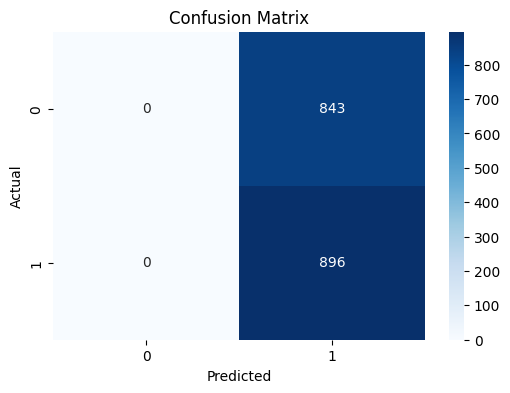

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# zeroR
print("ZeroR")
print("Accuracy: ", accuracy_score(y_test, y_pred_zeroR))
print("Precision: ", precision_score(y_test, y_pred_zeroR))
print("Recall: ", recall_score(y_test, y_pred_zeroR))
print("F1 Score: ", f1_score(y_test, y_pred_zeroR))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_zeroR), annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

KNN
Accuracy:  0.7722829212190915
Precision:  0.8094059405940595
Recall:  0.7299107142857143
F1 Score:  0.7676056338028169


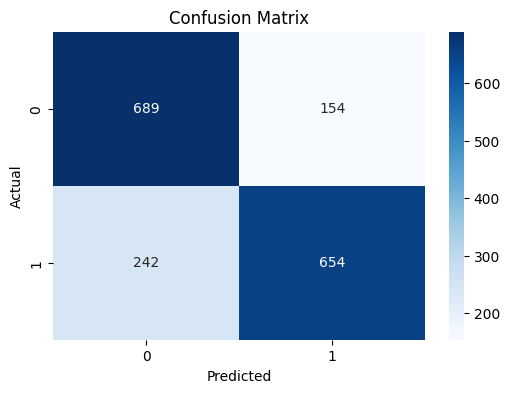

In [29]:
# KNN
print("KNN")
print("Accuracy: ", accuracy_score(y_test, y_pred_knn))
print("Precision: ", precision_score(y_test, y_pred_knn))
print("Recall: ", recall_score(y_test, y_pred_knn))
print("F1 Score: ", f1_score(y_test, y_pred_knn))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Gradient Boosting
Accuracy:  0.7550316273720529
Precision:  0.7605321507760532
Recall:  0.765625
F1 Score:  0.7630700778642937


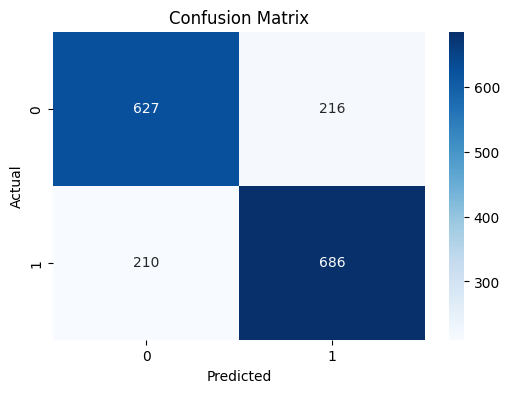

In [30]:
# Gradient Boosting
print("Gradient Boosting")
print("Accuracy: ", accuracy_score(y_test, y_pred_gb))
print("Precision: ", precision_score(y_test, y_pred_gb))
print("Recall: ", recall_score(y_test, y_pred_gb))
print("F1 Score: ", f1_score(y_test, y_pred_gb))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_gb), annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Random Forest
Accuracy:  0.7418056354226567
Precision:  0.8134642356241234
Recall:  0.6473214285714286
F1 Score:  0.7209446861404599


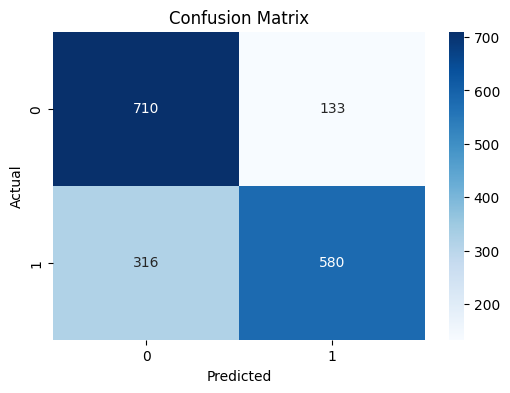

In [31]:
# Random Forest
print("Random Forest")
print("Accuracy: ", accuracy_score(y_test, y_pred_rf))
print("Precision: ", precision_score(y_test, y_pred_rf))
print("Recall: ", recall_score(y_test, y_pred_rf))
print("F1 Score: ", f1_score(y_test, y_pred_rf))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Conclusão

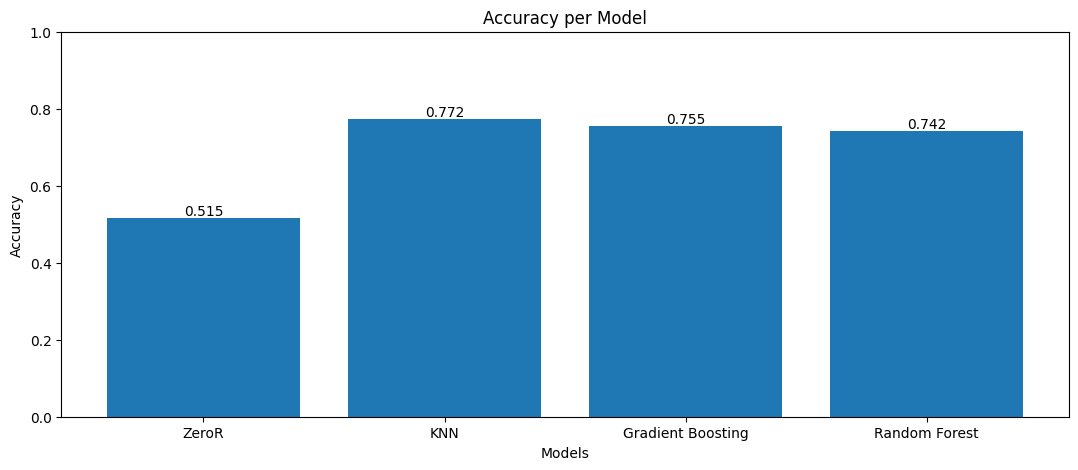

In [32]:
# accuracy table per model
plt.figure(figsize=(13, 5))
models = {
    'ZeroR': zeroR,
    'KNN': knn,
    'Gradient Boosting': gb,
    'Random Forest': rf
}
model_names = list(models.keys())
accuracies = [accuracy_score(y_test, y_pred_zeroR),
              accuracy_score(y_test, y_pred_knn),
              accuracy_score(y_test, y_pred_gb),
              accuracy_score(y_test, y_pred_rf)]

bars = plt.bar(model_names, accuracies)

for i in range(len(bars)):
  plt.text(i, accuracies[i], f'{accuracies[i]:.3f}', ha='center', va='bottom')

plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Accuracy per Model')
plt.ylim(0, 1.0)
plt.show()

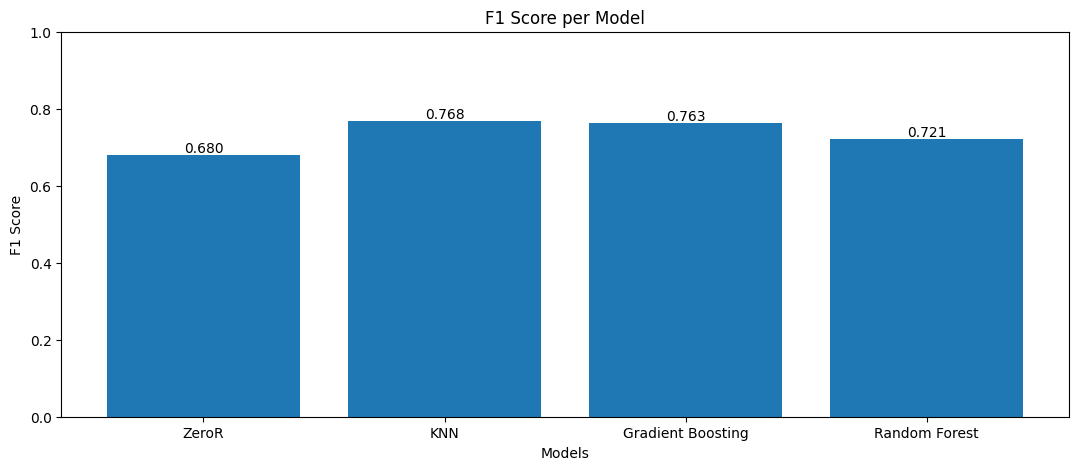

In [33]:
# f1 score table per model
plt.figure(figsize=(13, 5))

f1_scores = [f1_score(y_test, y_pred_zeroR),
             f1_score(y_test, y_pred_knn),
             f1_score(y_test, y_pred_gb),
             f1_score(y_test, y_pred_rf)]

bars = plt.bar(model_names, f1_scores)

for i in range(len(bars)):
  plt.text(i, f1_scores[i], f'{f1_scores[i]:.3f}', ha='center', va='bottom')

plt.xlabel('Models')
plt.ylabel('F1 Score')
plt.title('F1 Score per Model')
plt.ylim(0, 1.0)
plt.show()

In [34]:
# ranking
acc_rank = pd.DataFrame({'Model': [model.replace("\n", " ") for model in model_names[1:]],
                         'Accuracy': accuracies[1:]})
print('Accuracy Ranking')
print(acc_rank.sort_values(by=['Accuracy'], ascending=False), '\n')

f1_rank = pd.DataFrame({'Model': [model.replace("\n", " ") for model in model_names[1:]],
                        'F1 Score': f1_scores[1:]})
print('F1 Score Ranking')
print(f1_rank.sort_values(by=['F1 Score'], ascending=False), '\n')

Accuracy Ranking
               Model  Accuracy
0                KNN  0.772283
1  Gradient Boosting  0.755032
2      Random Forest  0.741806 

F1 Score Ranking
               Model  F1 Score
0                KNN  0.767606
1  Gradient Boosting  0.763070
2      Random Forest  0.720945 



In [46]:
print(acc_rank.iloc[0, 0])
model = models[acc_rank.iloc[0, 0]]
X_test = pd.read_csv('test.csv')
X_test[['Deck', 'CabinNum', 'Side']] = X_test['Cabin'].str.split('/', expand=True)
X_test = X_test.drop('Cabin', axis=1)
X_test_num = preproc.fit_transform(X_test)
prediction = model.predict(X_test_num)

submission = pd.DataFrame({'PassengerId': X_test['PassengerId'], 'Transported': prediction})
submission.to_csv(f'{acc_rank.iloc[0, 0]}_submission.csv', index=False)

KNN
     PassengerId  Transported
0        0013_01         True
1        0018_01        False
2        0019_01         True
3        0021_01         True
4        0023_01         True
...          ...          ...
4272     9266_02         True
4273     9269_01         True
4274     9271_01         True
4275     9273_01         True
4276     9277_01         True

[4277 rows x 2 columns]
